# 01 · Exploring the call data

Before building any model, we look at what is in the data and answer five questions:

1. Is the data clean?
2. How rare is a "yes", and what accuracy does a do-nothing guess get?
3. Which groups of customers say yes more often?
4. How strongly does call duration separate yes from no, and why can't we use it before calling?
5. Does the yes rate change over time?

Every finding ends in a decision for the modeling notebook.

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import MaxNLocator, PercentFormatter

from term_deposit.config import FIGURES_DIR
from term_deposit.data import load_data
from term_deposit.insights import subscription_rates

FIGURES_DIR.mkdir(parents=True, exist_ok=True)
pd.set_option("display.precision", 3)

# One blue for a single series, orange only when comparing two; gray for reference lines.
BLUE, ORANGE, MUTED = "#2a78d6", "#eb6834", "#898781"
plt.rcParams.update(
    {
        "figure.dpi": 110,
        "savefig.dpi": 150,
        "savefig.bbox": "tight",
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.edgecolor": "#c3c2b7",
        "axes.grid": True,
        "axes.axisbelow": True,
        "grid.color": "#e1e0d9",
        "grid.linewidth": 0.6,
        "axes.labelcolor": "#52514e",
        "xtick.color": "#52514e",
        "ytick.color": "#52514e",
        "axes.titlesize": 11,
        "axes.titleweight": "bold",
    }
)

## 1. Load and check the data

`load_data` stops with a clear message if any column is missing, empty or out of range,
so reaching the next line already means the file passed every check.

In [3]:
df = load_data()
print(f"{len(df):,} customers, {df.shape[1] - 1} columns plus the target y")
print("Duplicate rows:", df.duplicated().sum())
df.describe().T

40,000 customers, 13 columns plus the target y
Duplicate rows: 0


,count,mean,std,min,25%,50%,75%,max
age,40000.0,40.545,9.642,19.0,33.0,39.0,48.0,95.0
balance,40000.0,1274.278,2903.770,-8019.0,54.0,407.0,1319.0,102127.0
day,40000.0,16.017,8.278,1.0,8.0,17.0,21.0,31.0
duration,40000.0,254.824,259.366,0.0,100.0,175.0,313.0,4918.0
campaign,40000.0,2.882,3.239,1.0,1.0,2.0,3.0,63.0
y,40000.0,0.072,0.259,0.0,0.0,0.0,0.0,1.0


In [4]:
df.select_dtypes(exclude="number").describe().T

,count,unique,top,freq
job,40000,12,blue-collar,9383
marital,40000,3,married,24386
education,40000,4,secondary,20993
default,40000,2,no,39191
housing,40000,2,yes,24031
loan,40000,2,no,33070
contact,40000,3,cellular,24914
month,40000,11,may,13532


## 2. How rare is "yes"? The baseline to beat

In [5]:
yes_share = df["y"].mean()
print(f"Subscribed: {df['y'].sum():,} of {len(df):,} customers ({yes_share:.1%})")
print(f"Always answering 'no' is right {1 - yes_share:.1%} of the time, and finds no buyers.")

Subscribed: 2,896 of 40,000 customers (7.2%)
Always answering 'no' is right 92.8% of the time, and finds no buyers.


**Finding:** only about 7 in 100 customers subscribe. A "model" that always says *no* is
already 92.8% accurate, above the brief's 81% target, while finding nobody.

**Decision:** accuracy is reported because the brief asks for it, but models are compared on
how well they **find buyers**: ROC-AUC, PR-AUC, precision, recall and gains in notebook 02.

## 3. Who says yes? Rates by customer group

Each dot is a group's subscription rate, and its line is the **95% interval**: the range the
true rate plausibly lies in, given the group's size. A big group has a short line; a small group
has a long one, so a high rate from a few customers can't fool us. The dashed line is the
overall 7.2%. A group whose line sits entirely to one side of it really differs from average.

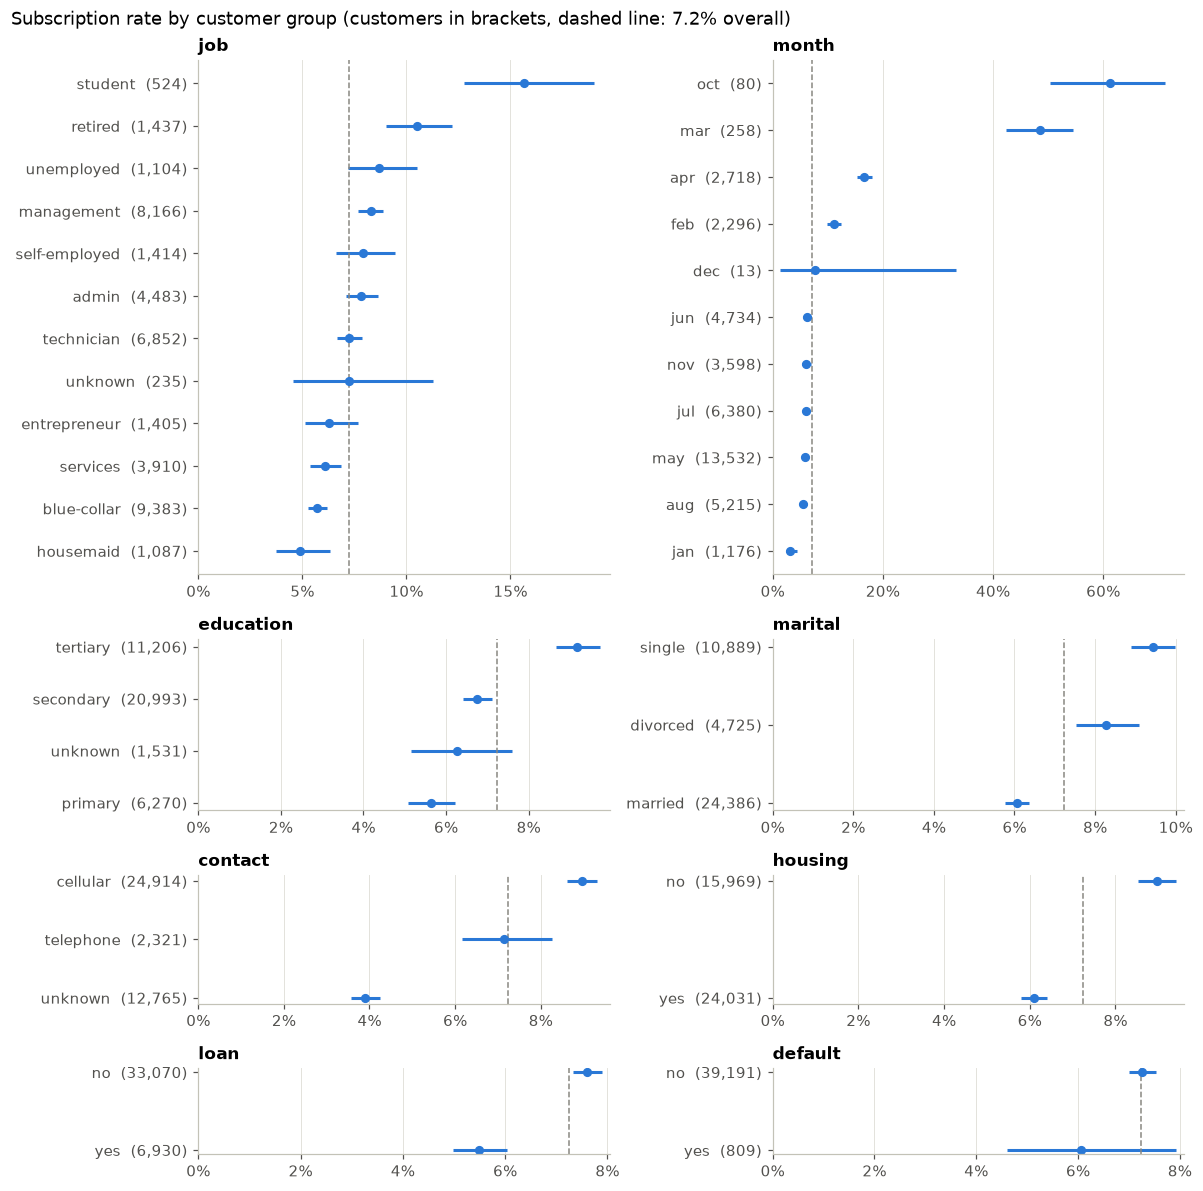

In [6]:
def plot_rates(table, ax, title, overall=yes_share):
    """Subscription rate per group as a dot with its 95% interval, against the overall rate."""
    rows = np.arange(len(table))
    ax.errorbar(
        table["rate"],
        rows,
        xerr=[table["rate"] - table["low"], table["high"] - table["rate"]],
        fmt="o",
        color=BLUE,
        elinewidth=2,
        markersize=5,
    )
    ax.axvline(overall, color=MUTED, linestyle="--", linewidth=1)
    labels = [f"{group}  ({n:,})" for group, n in zip(table.index, table["customers"], strict=True)]
    ax.set_yticks(rows, labels)
    ax.invert_yaxis()
    ax.grid(axis="y", visible=False)
    ax.set_xlim(left=0)  # rates start at 0%, so small gaps are not blown up
    ax.xaxis.set_major_locator(MaxNLocator(nbins=6, steps=[1, 2, 5, 10]))  # whole-% ticks
    ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
    ax.set_title(title, loc="left")


# Columns paired so each row's panels have a similar number of groups; row heights follow suit.
columns = ["job", "month", "education", "marital", "contact", "housing", "loan", "default"]
fig, axes = plt.subplots(4, 2, figsize=(11, 11), gridspec_kw={"height_ratios": [12, 4, 3, 2]})
for column, ax in zip(columns, axes.flat, strict=True):
    plot_rates(subscription_rates(df, column), ax, column)
fig.suptitle(
    "Subscription rate by customer group (customers in brackets, dashed line: 7.2% overall)",
    x=0.01,
    ha="left",
)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "rates_by_group.png")

**Findings:**

- **Job:** students (15.6%) and retired people (10.5%) say yes most often; blue-collar workers
  (5.7%) and housemaids (4.9%) least.
- **Loans:** customers **without a housing loan** subscribe at 9.0% vs 6.1% with one. Without a
  personal loan it's 7.6% vs 5.5%. Money already committed to a loan isn't free to lock away.
- **Marital status and education:** single customers (9.4%) and customers with tertiary
  education (9.2%) are above average.
- **Contact:** mobile ("cellular") 9.0% vs "unknown" 3.9%. Section 6 shows why "unknown" is
  low: it is really about *when* the customer was called.
- **Month:** October and March look spectacular (61% and 48%), but their intervals are wide
  because only 80 and 258 customers were called. Section 6 explains these months too.

## 4. Numbers: age, balance, day of month and number of calls

Numbers are grouped into bands so they can be read the same way:

- **Age** in life stages: young adults, mid-career, near retirement.
- **Balance** in fifths: five equal-sized groups of about 8,000 customers each. Balance is very
  skewed (from −8,019 € to 102,127 €), so equal-width bands would put almost everyone in one band.
- **Day** in weeks of the month.
- **Calls** this campaign: 1 to 5, then 6–10 and 11+.

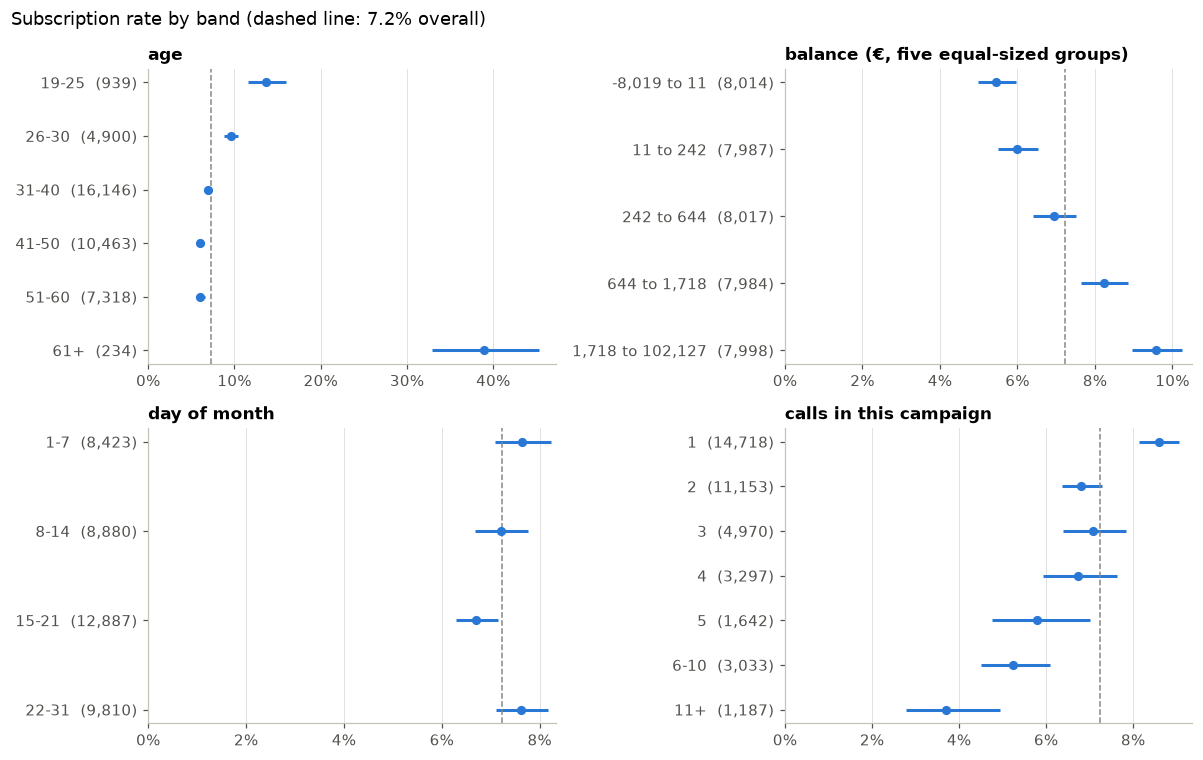

In [7]:
balance_fifths = pd.qcut(df["balance"], 5)
bands = {
    "age": pd.cut(
        df["age"],
        [18, 25, 30, 40, 50, 60, 100],
        labels=["19-25", "26-30", "31-40", "41-50", "51-60", "61+"],
    ),
    "balance (€, five equal-sized groups)": balance_fifths.cat.rename_categories(
        [f"{band.left:,.0f} to {band.right:,.0f}" for band in balance_fifths.cat.categories]
    ),
    "day of month": pd.cut(df["day"], [0, 7, 14, 21, 31], labels=["1-7", "8-14", "15-21", "22-31"]),
    "calls in this campaign": pd.cut(
        df["campaign"],
        [0, 1, 2, 3, 4, 5, 10, np.inf],
        labels=["1", "2", "3", "4", "5", "6-10", "11+"],
    ),
}

fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for (name, band), ax in zip(bands.items(), axes.flat, strict=True):
    plot_rates(subscription_rates(df.assign(group=band), "group", sort=False), ax, name)
fig.suptitle("Subscription rate by band (dashed line: 7.2% overall)", x=0.01, ha="left")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "rates_by_number.png")

In [8]:
subscription_rates(df.assign(group=bands["calls in this campaign"]), "group", sort=False)

,customers,subscribed,rate,low,high
group,,,,,
1,14718,1264,0.086,0.081,0.091
2,11153,760,0.068,0.064,0.073
3,4970,352,0.071,0.064,0.078
4,3297,222,0.067,0.059,0.076
5,1642,95,0.058,0.048,0.070
6-10,3033,159,0.052,0.045,0.061
11+,1187,44,0.037,0.028,0.049


**Findings:**

- **Age is U-shaped:** customers aged 25 or younger (13.6%) and over 60 (38.9%, a small group of 234)
  say yes far more often than those aged 31–60 (6–7%).
- **Balance:** the yes rate climbs steadily, from 5.5% in the lowest fifth to 9.6% in the highest.
  Customers with spare money can afford to lock it away.
- **Day of month:** flat (6.7%–7.6%), so expect it to matter little.
- **More calls, fewer yeses:** 8.6% on the first call, down to 3.7% after more than 10. Every
  extra call to the same customer is worth less than the one before.

These are associations, not causes: the data shows who says yes, not why. We can't conclude
that calling a customer less would make them say yes.

## 5. Call duration: a strong signal we can't use before calling

Median call length in seconds:
y
said no     164.0
said yes    629.0
Name: duration, dtype: float64


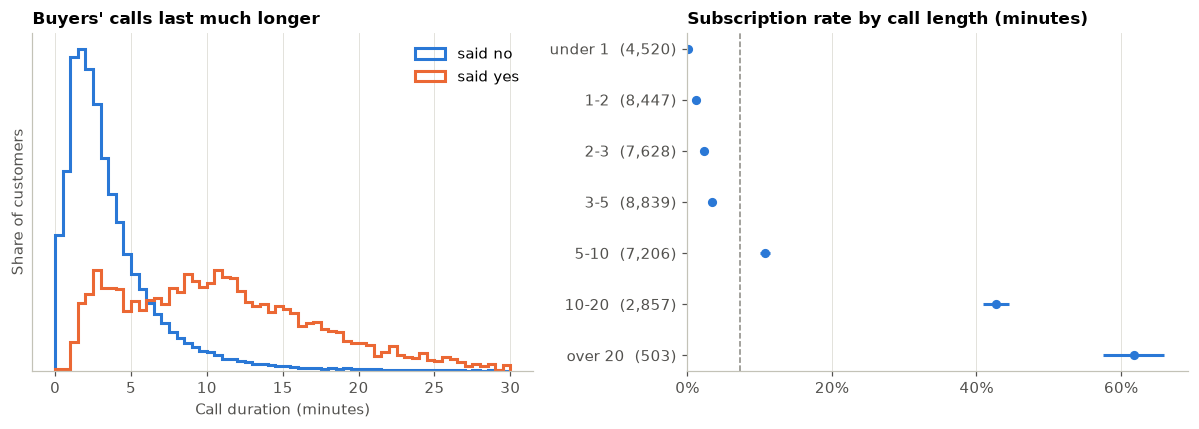

In [9]:
print("Median call length in seconds:")
print(df.groupby("y")["duration"].median().rename(index={0: "said no", 1: "said yes"}))

fig, (left, right) = plt.subplots(1, 2, figsize=(11, 4))
bins = np.arange(0, 30.5, 0.5)  # half-minute bins up to 30 minutes, which covers 99.8% of calls
for value, label, color in [(0, "said no", BLUE), (1, "said yes", ORANGE)]:
    left.hist(
        df.loc[df["y"] == value, "duration"] / 60,
        bins=bins,
        density=True,
        histtype="step",
        linewidth=2,
        color=color,
        label=label,
    )
left.set(xlabel="Call duration (minutes)", ylabel="Share of customers")
left.set_yticks([])
left.legend(frameon=False)
left.set_title("Buyers' calls last much longer", loc="left")

duration_minutes = pd.cut(
    df["duration"] / 60,
    [-np.inf, 1, 2, 3, 5, 10, 20, np.inf],
    labels=["under 1", "1-2", "2-3", "3-5", "5-10", "10-20", "over 20"],
)
plot_rates(
    subscription_rates(df.assign(group=duration_minutes), "group", sort=False),
    right,
    "Subscription rate by call length (minutes)",
)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "duration.png")

**Finding:** the typical "yes" call lasts about 10 minutes (629 s) and the typical "no" call less
than 3 (164 s). Under 1 minute almost nobody says yes; over 20 minutes most people do.

**Decision:** duration is only known **after the call has ended**. A model that uses it can't
decide whom to call, just as you can't pick a race winner from the finish-line photo. So we build:

- a **pre-call model** without `duration`, to choose whom to call and in what order;
- a **post-call model** with `duration`, to choose whom to call back after a conversation.

The left chart shows each group's own shape (`density=True`), because "no" customers outnumber
"yes" customers 13 to 1 and would otherwise flatten the "yes" curve.

## 6. Does the yes rate change over time?

The file has no year column, but the rows are in date order: the months run May, June, … ,
December, then January, … , June. Each time the month goes back from December to January, a new
year starts, so we can label every row with its calling period (Y1 = first year, Y2 = second).

**Why this matters:** the bank will use the model on **future** campaigns. If the yes rate depends
on *when* a customer was called, a model can learn the calendar instead of the customer.

In [10]:
MONTHS = ["jan", "feb", "mar", "apr", "may", "jun", "jul", "aug", "sep", "oct", "nov", "dec"]
month_number = df["month"].map(MONTHS.index)
year = 1 + (month_number.diff() < 0).cumsum()  # the month number drops only from Dec to Jan
period = df["month"].str.title() + " Y" + year.astype(str)
period = pd.Categorical(period, categories=period.unique(), ordered=True)

over_time = subscription_rates(df.assign(period=period), "period", sort=False)
unknown_contact = df["contact"].eq("unknown").groupby(period, observed=True).mean()
over_time.assign(contact_unknown=unknown_contact)

,customers,subscribed,rate,low,high,contact_unknown
period,,,,,,
May Y1,7957,258,0.032,0.029,0.037,1.000
Jun Y1,4486,201,0.045,0.039,0.051,1.000
Jul Y1,6380,384,0.060,0.055,0.066,0.037
Aug Y1,5215,288,0.055,0.049,0.062,0.002
Oct Y1,80,49,0.613,0.503,0.712,0.325
Nov Y1,3598,220,0.061,0.054,0.069,0.013
Dec Y1,13,1,0.077,0.014,0.333,0.231
Jan Y2,1176,38,0.032,0.024,0.044,0.000
Feb Y2,2296,255,0.111,0.099,0.125,0.000


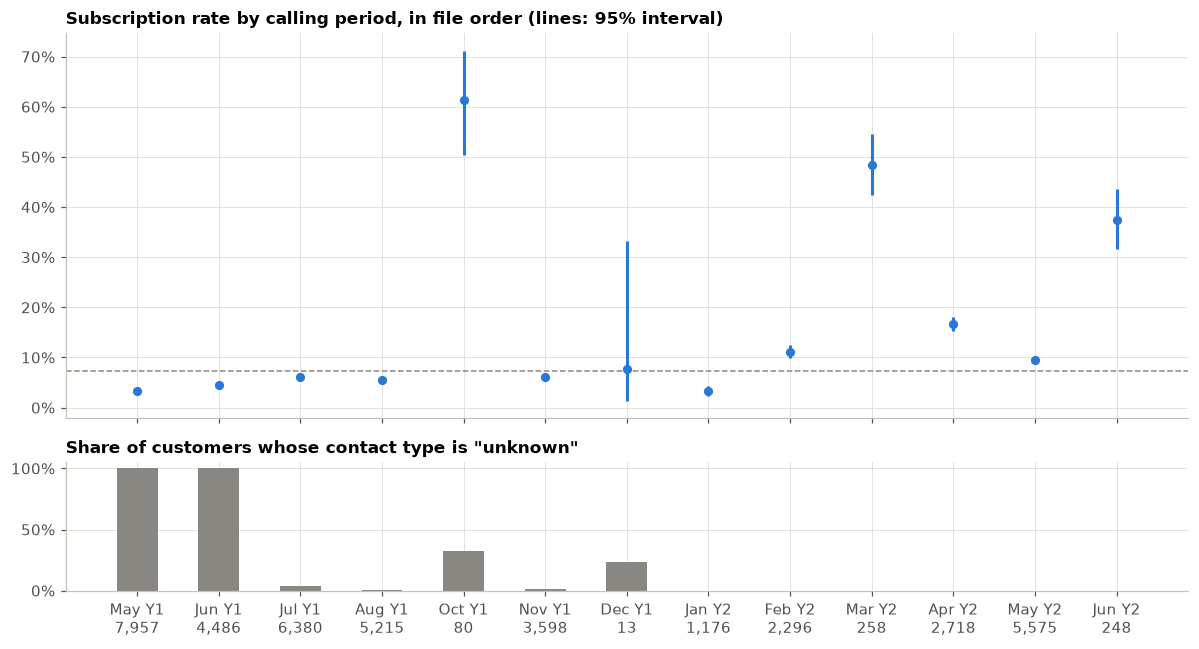

In [11]:
fig, (top, bottom) = plt.subplots(
    2, 1, figsize=(11, 6), sharex=True, gridspec_kw={"height_ratios": [3, 1]}
)
x = np.arange(len(over_time))
top.errorbar(
    x,
    over_time["rate"],
    yerr=[over_time["rate"] - over_time["low"], over_time["high"] - over_time["rate"]],
    fmt="o",
    color=BLUE,
    elinewidth=2,
    markersize=5,
)
top.axhline(yes_share, color=MUTED, linestyle="--", linewidth=1)
top.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
top.set_title(
    "Subscription rate by calling period, in file order (lines: 95% interval)", loc="left"
)

bottom.bar(x, unknown_contact, width=0.5, color=MUTED)
bottom.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
bottom.set_title('Share of customers whose contact type is "unknown"', loc="left")
bottom.set_xticks(
    x, [f"{p}\n{n:,}" for p, n in zip(over_time.index, over_time["customers"], strict=True)]
)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "rate_over_time.png")

**Findings:**

- **The same month name has very different rates:** May Y1 3.2% vs May Y2 9.6%. So `month` mostly
  records *which campaign period* the customer was called in, not a season that repeats.
- **The rate rises over time:** 3–6% in the big months of the first year, 10–17% in February, April
  and May of the second, plus small, very successful periods (Oct Y1: 80 calls, 61%; Mar Y2: 258
  calls, 48%).
- **`contact = "unknown"` exists only in May–June Y1:** the bank wasn't recording the channel then.
  Its low rate belongs to that early period, not to a phone channel.

**Decision:** keep `month` and `contact` (they help rank customers inside these campaigns), but in
notebook 02 also test every model on a **time-ordered split**: train on the earlier 80% of rows and
test on the later 20%. If the models do much worse there, month-based results won't carry over to
future campaigns.

## 7. Summary: what the data tells the modeling notebook

| Finding | Decision |
| --- | --- |
| Clean: no missing values, no duplicates, all values valid | No cleaning needed; keep "unknown" as its own value |
| Only 7.2% say yes; always-"no" is 92.8% accurate | Judge models on finding buyers: ROC-AUC, PR-AUC, precision, recall, gains |
| Duration separates yes from no, but only exists after the call | Two models: pre-call (no duration) and post-call (with duration) |
| Age (young and 60+), job, no housing loan, balance, mobile contact, few calls go with yes | Expect these among the top drivers in notebook 03 |
| Day of month is flat | Expect little importance |
| Month and "unknown" contact mostly mark *when* a call was made | Add a time-ordered test; treat month-based advice with care |